In [1]:
import numpy as np
import random
import pandas as pd
from tqdm import tqdm
import os
import matplotlib.pyplot as plt
from pathlib import Path

# Set professional style for all plots
plt.style.use('seaborn-v0_8')  # Use a clean style
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'sans-serif',
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 18,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Define consistent color palettes
colors_age = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green for 0-19, 20-64, 65+
colors_tfr = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Blue, Orange, Green, Red for TFRs
colors_change = ['#d62728', '#2ca02c']  # Red for decrease, Green for increase


In [2]:
data = Path("data")

In [3]:
datafiler = os.listdir(data)
datafiler.sort()
datafiler

['befolkning.csv',
 'befolkningsutvikling_2023_2073_1_1-1_66-2_1.csv',
 'befolkningsutvikling_2023_2073_1_1.csv',
 'befolkningsutvikling_2023_2073_1_66.csv',
 'befolkningsutvikling_2023_2073_2_1.csv',
 'befolkningsutvikling_2023_2123_1_1-1_66-2_1.csv',
 'netto_overføring.csv',
 'netto_overføring.xlsx',
 'netto_overføring_2024.csv',
 'oljefondets_utvikling.csv',
 'oljefondets_uvtikling.xls',
 'popfordeling_2023-2073_tfr1_1.csv',
 'popfordeling_2023-2073_tfr1_66.csv',
 'popfordeling_2023-2073_tfr2_1.csv',
 'popfordeling_2023-2123_tfr1_1.csv',
 'popfordeling_2023-2123_tfr1_66.csv',
 'popfordeling_2023-2123_tfr2_1.csv',
 'populasjon_2073_tfr1_1.csv',
 'populasjon_2073_tfr1_66.csv',
 'populasjon_2073_tfr2_1.csv',
 'populasjon_2123_tfr1_1.csv',
 'populasjon_2123_tfr1_66.csv',
 'populasjon_2123_tfr2_1.csv',
 'startpop_no.csv']

In [4]:
aktuelle_aar = 2073
aar = 2025
alder = 27
print(f"I året {aktuelle_aar} er jeg {aktuelle_aar - aar + alder} år gammel")

I året 2073 er jeg 75 år gammel


In [5]:
befolkning_23_63 = pd.read_csv(data / f"befolkningsutvikling_2023_{aktuelle_aar}_1_66.csv")#.iloc[:,1:]
befolkning_23_63.tail(5)

,år,pop_1.66
46,2069,5343600
47,2070,5308764
48,2071,5273839
49,2072,5238576
50,2073,5202335


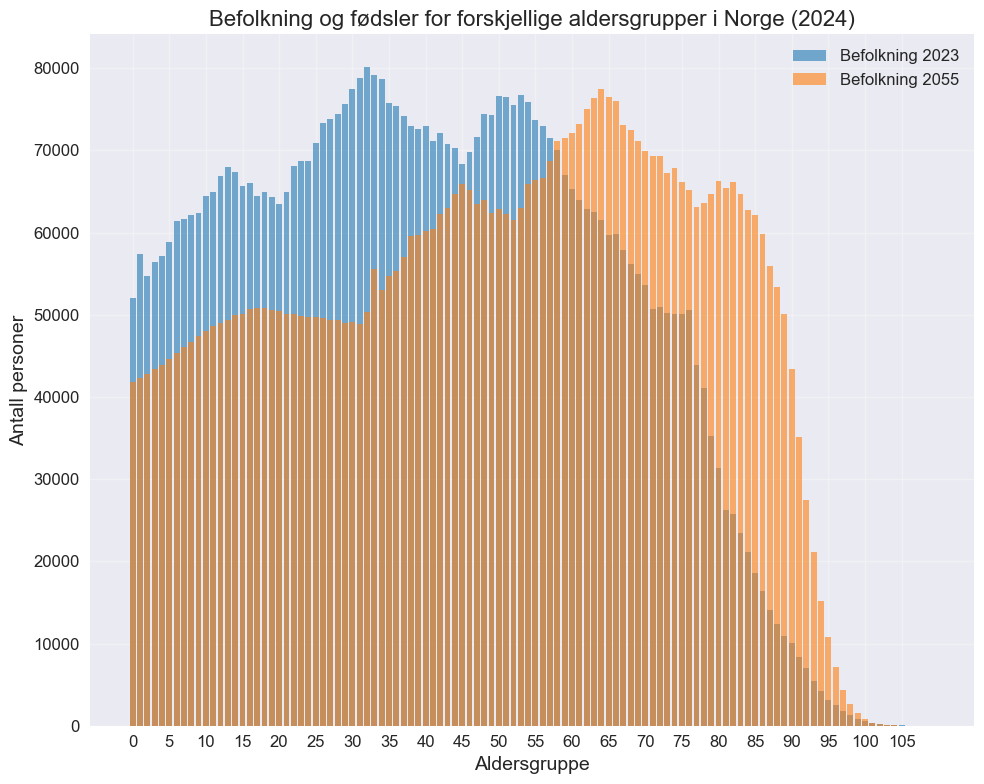

In [6]:
pop = pd.read_csv(data / 'popfordeling_2023-2073_tfr1_66.csv').iloc[:,:93]

year_from = 2023
year_to =  2023 + 32

pop = pop[["sex","alder", f"pop_{year_from}", f"pop_{year_to}"]]

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))
pop_total = pop.groupby("alder")[["pop_2023", "pop_2055"]].sum().reset_index()

ax.bar(pop_total.index, pop_total[f"pop_{year_from}"], color=colors_tfr[0], alpha=0.6, label='Befolkning 2023')
ax.bar(pop_total.index, pop_total[f"pop_{year_to}"], color=colors_tfr[1], alpha=0.6, label='Befolkning 2055')



ax.set_ylabel('Antall personer')
ax.set_xlabel('Aldersgruppe')
ax.set_title('Befolkning og fødsler for forskjellige aldersgrupper i Norge (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total.index), 5))
ax.set_xticklabels(range(0, len(pop_total.index), 5))

plt.tight_layout()


In [7]:
pop

,sex,alder,pop_2023,pop_2055
0,K,0,25310.0,20938.0
1,K,1,28037.0,21317.0
2,K,2,26820.0,21447.0
3,K,3,27466.0,21677.0
4,K,4,27692.0,21952.0
...,...,...,...,...
215,M,105,28.0,2.0
216,M,106,NaN,1.0
217,M,107,NaN,2.0
218,M,108,NaN,NaN


In [8]:
oljefondet = pd.read_csv("data/oljefondets_utvikling.csv", delimiter=";")
cols = ["år", "kronekurs", "avkastning", "tilførsel", "totalt"]
oljefondet.columns = cols

oljefondet[["kronekurs", "avkastning", "tilførsel", "totalt"]] = oljefondet[["kronekurs", "avkastning", "tilførsel", "totalt"]] * 1e9
oljefondet

,år,kronekurs,avkastning,tilførsel,totalt
0,1998,1.833000e+10,1.220000e+10,1.413100e+11,1.720000e+11
1,1999,2.124000e+10,3.544000e+10,1.657300e+11,2.220000e+11
2,2000,2.952000e+10,4.133000e+10,3.156000e+11,3.860000e+11
3,2001,1.409000e+10,3.274000e+10,5.668600e+11,6.140000e+11
4,2002,-8.656000e+10,3.320000e+09,6.922400e+11,6.090000e+11
5,2003,-4.574000e+10,9.490000e+10,7.961500e+11,8.450000e+11
6,2004,-9.490000e+10,1.769800e+11,9.343200e+11,1.016000e+12
7,2005,-5.923000e+10,3.036700e+11,1.154610e+12,1.399000e+12
8,2006,-8.705000e+10,4.278300e+11,1.442910e+12,1.784000e+12
9,2007,-2.405500e+11,5.026400e+11,1.756560e+12,2.019000e+12


In [9]:
oljefondet["totalt"]

0     1.720000e+11
1     2.220000e+11
2     3.860000e+11
3     6.140000e+11
4     6.090000e+11
5     8.450000e+11
6     1.016000e+12
7     1.399000e+12
8     1.784000e+12
9     2.019000e+12
10    2.275000e+12
11    2.640000e+12
12    3.077000e+12
13    3.312000e+12
14    3.816000e+12
15    5.038000e+12
16    6.431000e+12
17    7.475000e+12
18    7.510000e+12
19    8.488000e+12
20    8.256000e+12
21    1.008800e+13
22    1.091400e+13
23    1.234000e+13
24    1.242900e+13
25    1.575700e+13
26    1.974200e+13
27    2.126800e+13
Name: totalt, dtype: float64

In [10]:
(oljefondet["totalt"] / 5.7e6)

0     3.017544e+04
1     3.894737e+04
2     6.771930e+04
3     1.077193e+05
4     1.068421e+05
5     1.482456e+05
6     1.782456e+05
7     2.454386e+05
8     3.129825e+05
9     3.542105e+05
10    3.991228e+05
11    4.631579e+05
12    5.398246e+05
13    5.810526e+05
14    6.694737e+05
15    8.838596e+05
16    1.128246e+06
17    1.311404e+06
18    1.317544e+06
19    1.489123e+06
20    1.448421e+06
21    1.769825e+06
22    1.914737e+06
23    2.164912e+06
24    2.180526e+06
25    2.764386e+06
26    3.463509e+06
27    3.731228e+06
Name: totalt, dtype: float64

In [11]:
20_000_000_000 / 5_700_000

3508.7719298245615

<Axes: xlabel='år'>

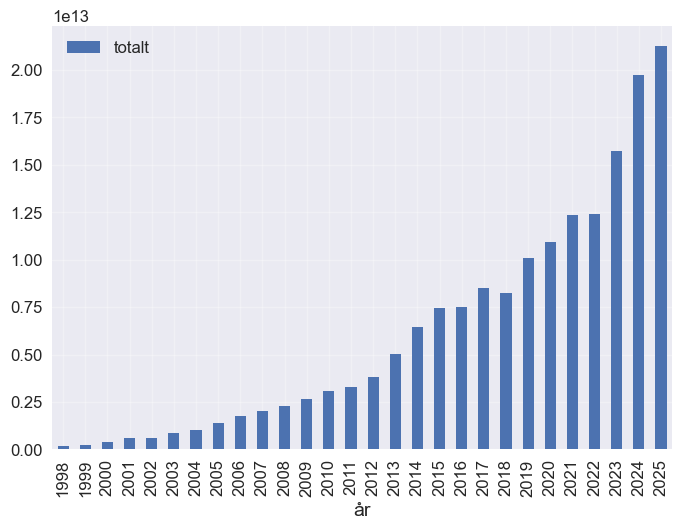

In [12]:
oljefondet.plot(x="år", y="totalt", kind="bar")

In [15]:
oljefondet

,år,kronekurs,avkastning,tilførsel,totalt,pct_change
0,1998,1.833000e+10,1.220000e+10,1.413100e+11,1.720000e+11,NaN
1,1999,2.124000e+10,3.544000e+10,1.657300e+11,2.220000e+11,29.069767
2,2000,2.952000e+10,4.133000e+10,3.156000e+11,3.860000e+11,73.873874
3,2001,1.409000e+10,3.274000e+10,5.668600e+11,6.140000e+11,59.067358
4,2002,-8.656000e+10,3.320000e+09,6.922400e+11,6.090000e+11,-0.814332
5,2003,-4.574000e+10,9.490000e+10,7.961500e+11,8.450000e+11,38.752053
6,2004,-9.490000e+10,1.769800e+11,9.343200e+11,1.016000e+12,20.236686
7,2005,-5.923000e+10,3.036700e+11,1.154610e+12,1.399000e+12,37.696850
8,2006,-8.705000e+10,4.278300e+11,1.442910e+12,1.784000e+12,27.519657
9,2007,-2.405500e+11,5.026400e+11,1.756560e+12,2.019000e+12,13.172646


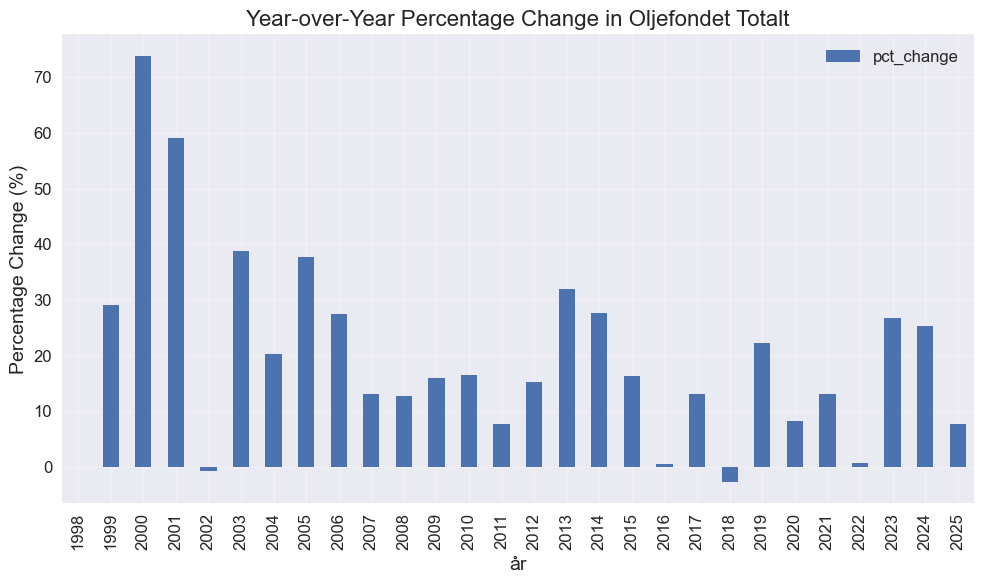

In [ ]:
# Calculate year-over-year percentage change in 'totalt'
oljefondet['pct_change'] = oljefondet['totalt'].pct_change() * 100

# Plot the percentage change
oljefondet.plot(x="år", y="pct_change", kind="bar", figsize=(10, 6))
plt.ylabel('Percentage Change (%)')
plt.title('Year-over-Year Percentage Change in Oljefondet Totalt')
plt.grid(True, alpha=0.3)
plt.tight_layout()

In [183]:
# netto overføring
netto_overforing = pd.read_csv("data/netto_overføring_2024.csv", delimiter=";")
netto_overforing
netto_overforing = netto_overforing.iloc[:, 0:2]
netto_overforing
netto_overforing.columns = ["alder", "netto_overforing"]
netto_overforing

,alder,netto_overforing
0,0,260.089686
1,1,360.538117
2,2,371.300448
3,3,425.112108
4,4,346.188341
...,...,...
105,104,1600.000000
106,105,1601.000000
107,106,1602.000000
108,107,1603.000000


In [184]:
pop_total = pd.read_csv(data / 'popfordeling_2023-2073_tfr1_66.csv').iloc[:,:93]
pop_total_m_overforing = pop_total.merge(netto_overforing, on="alder")

for year in range(2023, 2074):
    pop_total_m_overforing[f"pop_{year}"] = (pop_total_m_overforing[f"pop_{year}"] * pop_total_m_overforing["netto_overforing"]).fillna(0) * 1000


In [185]:
pop_total_m_overforing

,sex,alder,pop_2023,pop_2024,pop_2025,pop_2026,pop_2027,pop_2028,pop_2029,pop_2030,...,pop_2065,pop_2066,pop_2067,pop_2068,pop_2069,pop_2070,pop_2071,pop_2072,pop_2073,netto_overforing
0,K,0,6.582870e+09,6.562063e+09,6.549058e+09,6.577668e+09,6.590933e+09,6.634888e+09,6.635928e+09,6.591713e+09,...,5.279561e+09,5.220780e+09,5.236646e+09,5.158879e+09,5.212457e+09,5.140152e+09,5.144314e+09,5.143794e+09,5.119085e+09,260.089686
1,K,1,1.010841e+10,9.118370e+09,9.083397e+09,9.071860e+09,9.110077e+09,9.127743e+09,9.187953e+09,9.187953e+09,...,7.281788e+09,7.309910e+09,7.231313e+09,7.252945e+09,7.144423e+09,7.218694e+09,7.118104e+09,7.125315e+09,7.123152e+09,360.538117
2,K,2,9.958278e+09,1.040161e+10,9.384619e+09,9.346746e+09,9.332637e+09,9.372737e+09,9.389817e+09,9.451453e+09,...,7.476135e+09,7.493586e+09,7.518834e+09,7.440861e+09,7.460540e+09,7.350635e+09,7.427494e+09,7.321302e+09,7.330956e+09,371.300448
3,K,3,1.167613e+10,1.138875e+10,1.189634e+10,1.073196e+10,1.069029e+10,1.067584e+10,1.072430e+10,1.073791e+10,...,8.579613e+09,8.550705e+09,8.570685e+09,8.599168e+09,8.508194e+09,8.536251e+09,8.408717e+09,8.495015e+09,8.375984e+09,425.112108
4,K,4,9.586648e+09,9.501485e+09,9.264346e+09,9.680465e+09,8.731562e+09,8.697290e+09,8.683788e+09,8.724639e+09,...,6.944884e+09,6.980542e+09,6.955270e+09,6.972579e+09,6.994735e+09,6.925152e+09,6.942115e+09,6.839989e+09,6.911996e+09,346.188341
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,M,104,8.000000e+06,9.600000e+06,6.400000e+06,9.600000e+06,1.600000e+06,3.200000e+06,4.800000e+06,6.400000e+06,...,2.240000e+07,1.760000e+07,2.720000e+07,2.880000e+07,4.480000e+07,2.240000e+07,3.360000e+07,3.200000e+07,3.200000e+07,1600.000000
216,M,105,4.482800e+07,1.601000e+06,1.601000e+06,3.202000e+06,1.601000e+06,0.000000e+00,1.601000e+06,0.000000e+00,...,1.280800e+07,4.803000e+06,1.120700e+07,3.202000e+06,9.606000e+06,1.761100e+07,8.005000e+06,1.280800e+07,1.120700e+07,1601.000000
217,M,106,0.000000e+00,3.204000e+06,0.000000e+00,1.602000e+06,1.602000e+06,0.000000e+00,0.000000e+00,0.000000e+00,...,3.204000e+06,1.602000e+06,4.806000e+06,3.204000e+06,0.000000e+00,4.806000e+06,6.408000e+06,4.806000e+06,3.204000e+06,1602.000000
218,M,107,0.000000e+00,0.000000e+00,1.603000e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,1.603000e+06,1.603000e+06,0.000000e+00,0.000000e+00,0.000000e+00,1.603000e+06,3.206000e+06,1.603000e+06,1603.000000


In [186]:
pop_sum = pop_total_m_overforing[[f"pop_{year}" for year in range(2023, 2074)]].sum().reset_index()
pop_sum.columns = ["aar", "sum_overforing"]

In [187]:
pop_sum["aar"] = range(2023,2074)
pop_sum

,aar,sum_overforing
0,2023,3.254548e+11
1,2024,3.397290e+11
2,2025,3.569238e+11
3,2026,3.764470e+11
4,2027,3.980039e+11
5,2028,4.225272e+11
6,2029,4.453114e+11
7,2030,4.703288e+11
8,2031,4.965772e+11
9,2032,5.232364e+11


<Axes: xlabel='aar'>

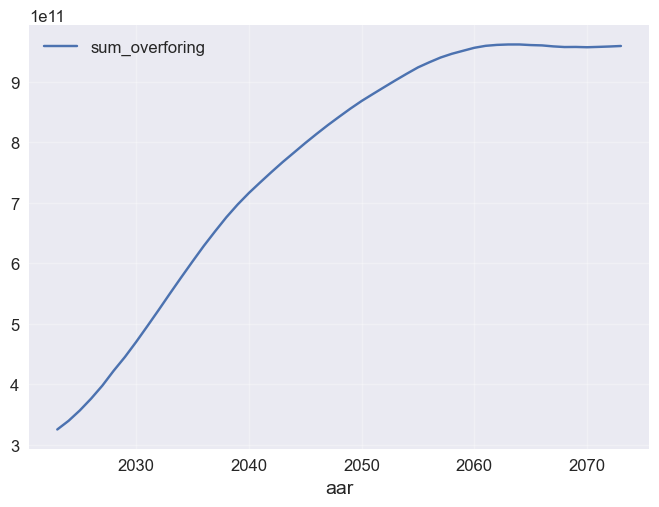

In [188]:
pop_sum.plot(x="aar", y="sum_overforing")


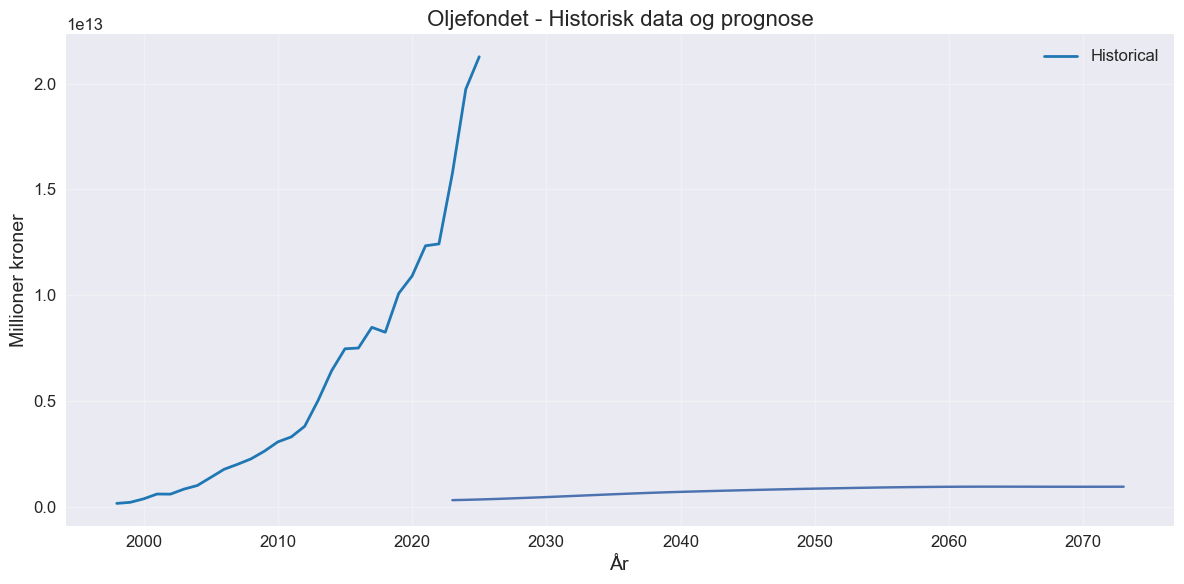

In [189]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(oljefondet['år'], oljefondet['totalt'], label='Historical', color=colors_tfr[0], linewidth=2)
# ax.plot(forecast_df['år'], forecast_df['totalt'], label='Forecast', color=colors_tfr[1], linewidth=2, linestyle='--')
ax.plot(pop_sum["aar"], pop_sum["sum_overforing"])
ax.set_xlabel('År')
ax.set_ylabel('Millioner kroner')
ax.set_title('Oljefondet - Historisk data og prognose')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

In [166]:
pop_total_m_overforing["netto_overforing_2023_millioner"] = (
    (pop_total_m_overforing["pop_2023"] * pop_total_m_overforing["netto_overforing"])
    /1e3
)

pop_total_m_overforing["netto_overforing_2055_millioner"] = (
    (pop_total_m_overforing["pop_2055"] * pop_total_m_overforing["netto_overforing"])
    /1e3
)

In [167]:
pop_total_m_overforing.to_clipboard()

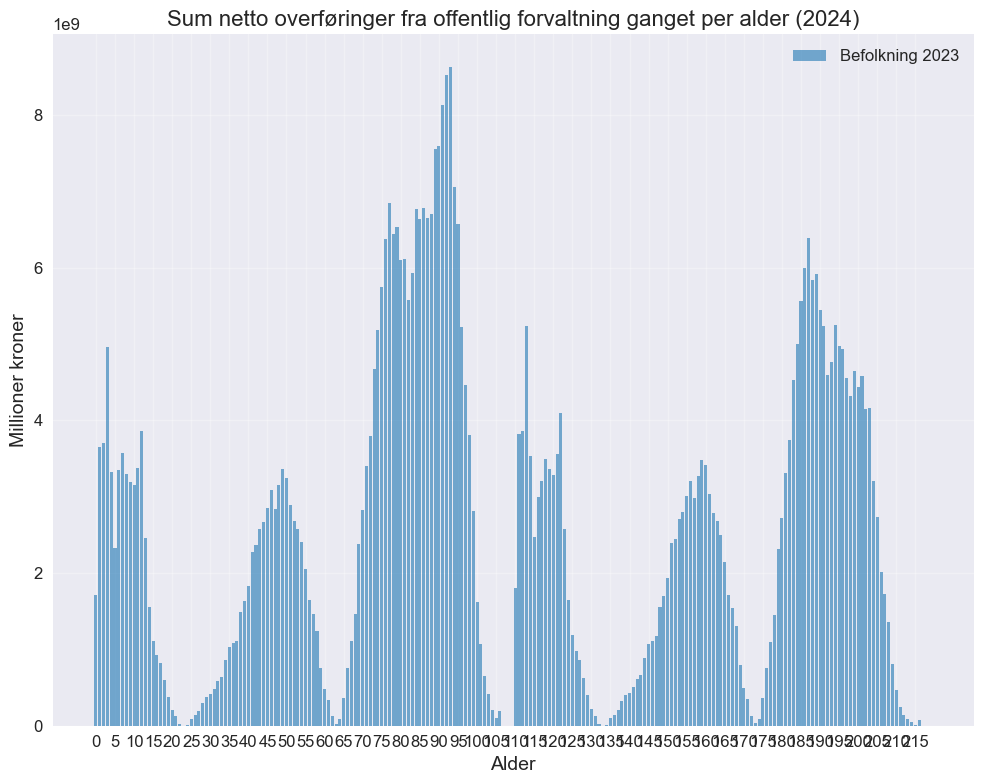

In [168]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))


ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"netto_overforing_2023_millioner"], color=colors_tfr[0], alpha=0.6, label='Befolkning 2023')



ax.set_ylabel('Millioner kroner')
ax.set_xlabel('Alder')
ax.set_title('Sum netto overføringer fra offentlig forvaltning ganget per alder (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total_m_overforing.index), 5))
ax.set_xticklabels(range(0, len(pop_total_m_overforing.index), 5))

plt.tight_layout()

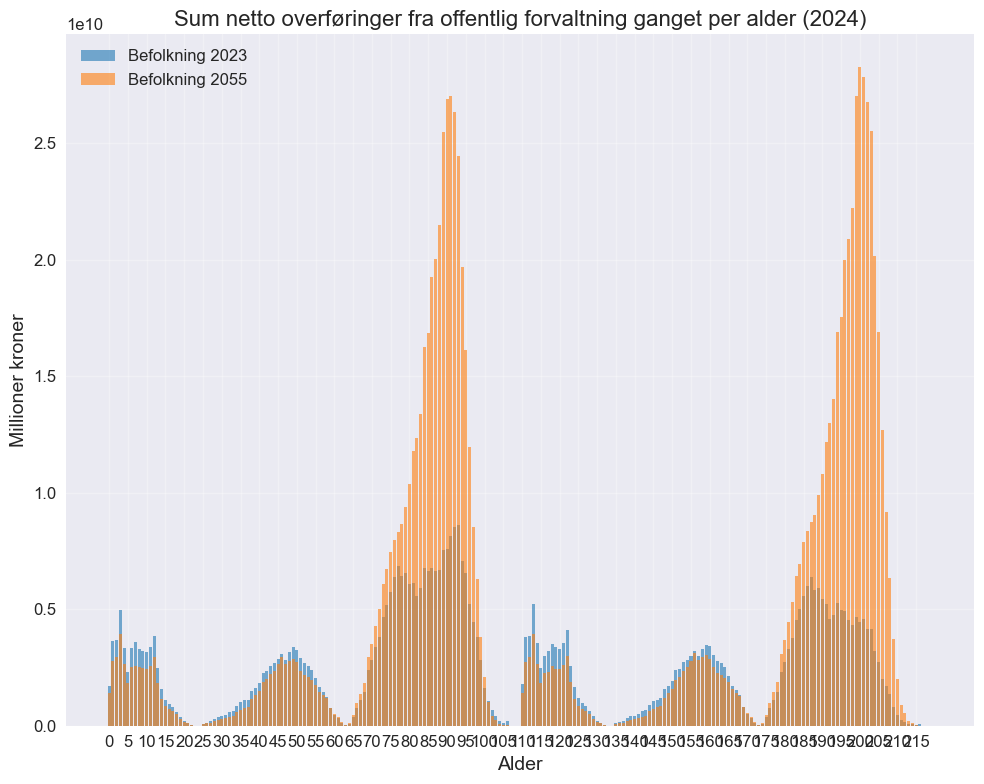

In [169]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))


ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"netto_overforing_2023_millioner"], color=colors_tfr[0], alpha=0.6, label='Befolkning 2023')
ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"netto_overforing_2055_millioner"], color=colors_tfr[1], alpha=0.6, label='Befolkning 2055')



ax.set_ylabel('Millioner kroner')
ax.set_xlabel('Alder')
ax.set_title('Sum netto overføringer fra offentlig forvaltning ganget per alder (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total_m_overforing.index), 5))
ax.set_xticklabels(range(0, len(pop_total_m_overforing.index), 5))

plt.tight_layout()

In [136]:
pop_total_m_overforing["diff"] = pop_total_m_overforing["netto_overforing_2055_millioner"] - pop_total_m_overforing["netto_overforing_2023_millioner"]
pop_total_m_overforing

,alder,pop_2023,pop_2055,netto_overforing,netto_overforing_2023_millioner,netto_overforing_2055_millioner,diff
0,0,51991.0,41826.0,260.089686,13522.322870,10878.511211,-2643.811659
1,1,57415.0,42274.0,360.538117,20700.295965,15241.388341,-5458.907623
2,2,54778.0,42757.0,371.300448,20339.095962,15875.693272,-4463.402690
3,3,56455.0,43375.0,425.112108,23999.704035,18439.237667,-5560.466367
4,4,57146.0,43928.0,346.188341,19783.278923,15207.361435,-4575.917489
...,...,...,...,...,...,...,...
105,104,44.0,29.0,1600.000000,70.400000,46.400000,-24.000000
106,105,104.0,7.0,1601.000000,166.504000,11.207000,-155.297000
107,106,0.0,4.0,1602.000000,0.000000,6.408000,6.408000
108,107,0.0,3.0,1603.000000,0.000000,4.809000,4.809000


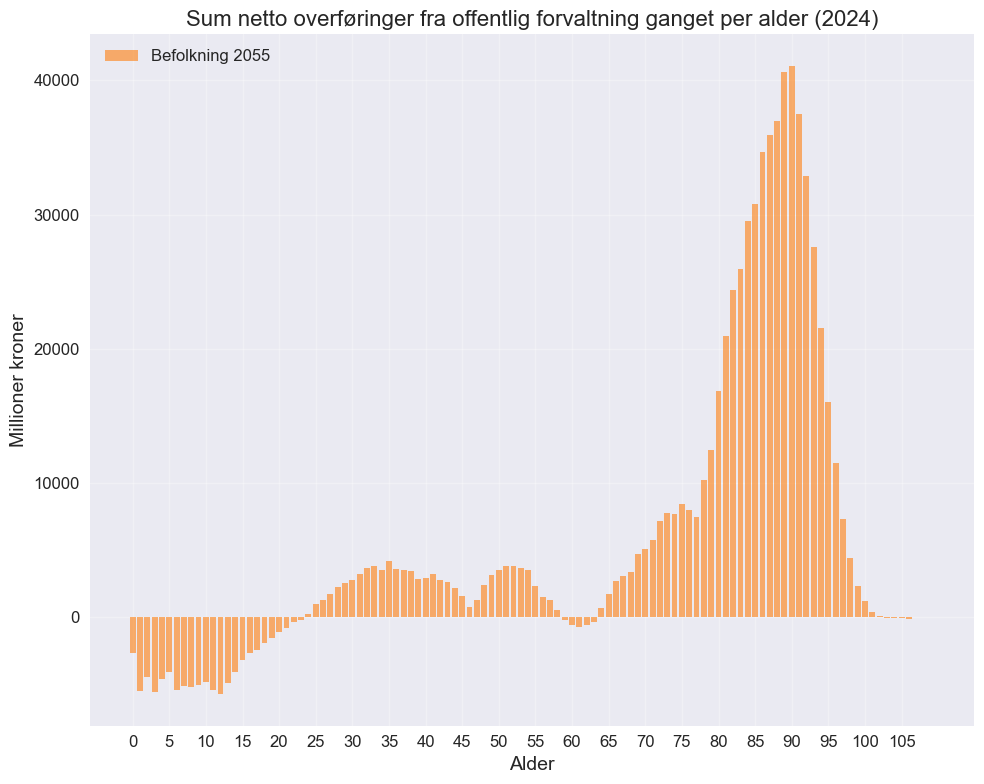

In [137]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"diff"], color=colors_tfr[1], alpha=0.6, label='Befolkning 2055')


ax.set_ylabel('Millioner kroner')
ax.set_xlabel('Alder')
ax.set_title('Sum netto overføringer fra offentlig forvaltning ganget per alder (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total_m_overforing.index), 5))
ax.set_xticklabels(range(0, len(pop_total_m_overforing.index), 5))

plt.tight_layout()

In [112]:
# Sum of negative values and positive values in netto_overforing_2055_millioner
negative_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2023_millioner"] < 0, "netto_overforing_2023_millioner"].sum()
positive_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2023_millioner"] > 0, "netto_overforing_2023_millioner"].sum()

print(f"Sum of negative values: {round(negative_sum,2)}")
print(f"Sum of positive values: {round(positive_sum,2)}")
print(round(-negative_sum / positive_sum,2) * 100, "%")

Sum of negative values: -540843.3
Sum of positive values: 866298.06
62.0 %


In [129]:
# Sum of negative values and positive values in netto_overforing_2055_millioner
negative_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2055_millioner"] < 0, "netto_overforing_2055_millioner"].sum()
positive_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2070_millioner"] > 0, "netto_overforing_2070_millioner"].sum()

print(f"Sum of negative values: {round(negative_sum,2)}")
print(f"Sum of positive values: {round(positive_sum,2)}")
print(round(-negative_sum / positive_sum,2) * 100, "%")

KeyError: 'netto_overforing_2070_millioner'

In [114]:
pop_total_m_overforing

,alder,pop_2023,pop_2055,netto_overforing,netto_overforing_2023_millioner,netto_overforing_2055_millioner
0,0,51991.0,41826.0,260.089686,13522.322870,10878.511211
1,1,57415.0,42274.0,360.538117,20700.295965,15241.388341
2,2,54778.0,42757.0,371.300448,20339.095962,15875.693272
3,3,56455.0,43375.0,425.112108,23999.704035,18439.237667
4,4,57146.0,43928.0,346.188341,19783.278923,15207.361435
...,...,...,...,...,...,...
105,104,44.0,29.0,1600.000000,70.400000,46.400000
106,105,104.0,7.0,1601.000000,166.504000,11.207000
107,106,0.0,4.0,1602.000000,0.000000,6.408000
108,107,0.0,3.0,1603.000000,0.000000,4.809000


In [115]:
pop

,sex,alder,pop_2023,pop_2024,pop_2025,pop_2026,pop_2027,pop_2028,pop_2029,pop_2030,...,pop_2065,pop_2066,pop_2067,pop_2068,pop_2069,pop_2070,pop_2071,pop_2072,pop_2073,age_group
0,K,0,25310.0,25230.0,25180.0,25290.0,25341.0,25510.0,25514.0,25344.0,...,20299.0,20073.0,20134.0,19835.0,20041.0,19763.0,19779.0,19777.0,19682.0,0-19
1,K,1,28037.0,25291.0,25194.0,25162.0,25268.0,25317.0,25484.0,25484.0,...,20197.0,20275.0,20057.0,20117.0,19816.0,20022.0,19743.0,19763.0,19757.0,0-19
2,K,2,26820.0,28014.0,25275.0,25173.0,25135.0,25243.0,25289.0,25455.0,...,20135.0,20182.0,20250.0,20040.0,20093.0,19797.0,20004.0,19718.0,19744.0,0-19
3,K,3,27466.0,26790.0,27984.0,25245.0,25147.0,25113.0,25227.0,25259.0,...,20182.0,20114.0,20161.0,20228.0,20014.0,20080.0,19780.0,19983.0,19703.0,0-19
4,K,4,27692.0,27446.0,26761.0,27963.0,25222.0,25123.0,25084.0,25202.0,...,20061.0,20164.0,20091.0,20141.0,20205.0,20004.0,20053.0,19758.0,19966.0,0-19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,M,105,28.0,1.0,1.0,2.0,1.0,NaN,1.0,NaN,...,8.0,3.0,7.0,2.0,6.0,11.0,5.0,8.0,7.0,65+
216,M,106,NaN,2.0,NaN,1.0,1.0,NaN,NaN,NaN,...,2.0,1.0,3.0,2.0,NaN,3.0,4.0,3.0,2.0,65+
217,M,107,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,1.0,1.0,NaN,NaN,NaN,1.0,2.0,1.0,65+
218,M,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65+


In [116]:
# Function to calculate netto_overforing_pct for a given population dataframe
def calculate_netto_overforing_pct(pop_df, netto_overforing_rates):
    # Aggregate pop by age (summing over sex)
    pop_agg = pop_df.groupby("alder").sum().reset_index()
    
    # Merge with netto_overforing rates
    pop_merged = pop_agg.merge(netto_overforing_rates, on="alder")
    
    # Generate netto_overforing columns for all years
    for aar in range(2023, 2074):
        pop_col = f"pop_{aar}"
        res_col = f"netto_overforing_{aar}_millioner"
        
        if pop_col in pop_merged.columns:
            pop_merged[res_col] = (pop_merged[pop_col] * pop_merged["netto_overforing"]) / 1e3
    
    # Calculate the sums and percentages
    netto_overforing_pct = pd.DataFrame(columns=["aar", "negativ_sum", "positiv_sum", "prosent"])
    
    for aar in range(2023, 2074):
        col_name = f"netto_overforing_{aar}_millioner"
        
        if col_name in pop_merged.columns:
            negative_sum = pop_merged.loc[lambda x: x[col_name] < 0, col_name].sum()
            positive_sum = pop_merged.loc[lambda x: x[col_name] > 0, col_name].sum()
            
            prosent = round(-negative_sum / positive_sum, 2) * 100 if positive_sum != 0 else 0
            
            new_row = pd.DataFrame([{
                "aar": aar,
                "negativ_sum": round(negative_sum, 2),
                "positiv_sum": round(positive_sum, 2),
                "prosent": prosent
            }])
            netto_overforing_pct = pd.concat([netto_overforing_pct, new_row], ignore_index=True)
    
    return netto_overforing_pct

# Calculate for all three dataframes
netto_overforing_pct_1 = calculate_netto_overforing_pct(pop_1, netto_overforing)
netto_overforing_pct_2 = calculate_netto_overforing_pct(pop_2, netto_overforing)
netto_overforing_pct_3 = calculate_netto_overforing_pct(pop_3, netto_overforing)

# Add labels for each TFR scenario
netto_overforing_pct_1["tfr"] = "TFR 1.66"
netto_overforing_pct_2["tfr"] = "TFR 2.1"
netto_overforing_pct_3["tfr"] = "TFR 1.1"

# Combine all three
netto_overforing_all = pd.concat([netto_overforing_pct_1, netto_overforing_pct_2, netto_overforing_pct_3], ignore_index=True)
netto_overforing_all


/var/folders/0k/kjly72p17y1gxqhyj4zvz9yh0000gn/T/ipykernel_5845/2934352278.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pop_merged[res_col] = (pop_merged[pop_col] * pop_merged["netto_overforing"]) / 1e3
/var/folders/0k/kjly72p17y1gxqhyj4zvz9yh0000gn/T/ipykernel_5845/2934352278.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pop_merged[res_col] = (pop_merged[pop_col] * pop_merged["netto_overforing"]) / 1e3
/var/folders/0k/kjly72p17y1gxqhyj4zvz9yh0000gn/T/ipykernel_5845/2934352278.py:15: PerformanceWarning: DataFrame 

,aar,negativ_sum,positiv_sum,prosent,tfr
0,2023,-540843.3,866298.06,62.0,TFR 1.66
1,2024,-541306.16,881035.19,61.0,TFR 1.66
2,2025,-541339.56,898263.39,60.0,TFR 1.66
3,2026,-540982.02,917429.02,59.0,TFR 1.66
4,2027,-540270.13,938274.04,58.0,TFR 1.66
...,...,...,...,...,...
148,2069,-356039.99,1245021.33,29.0,TFR 1.1
149,2070,-348171.54,1238594.47,28.0,TFR 1.1
150,2071,-340213.49,1232995.07,28.0,TFR 1.1
151,2072,-332213.17,1228134.04,27.0,TFR 1.1


In [140]:
netto_overforing_all.loc[lambda x: x.tfr == "TFR 1.66"]


,aar,negativ_sum,positiv_sum,prosent,tfr
0,2023,-540843.3,866298.06,62.0,TFR 1.66
1,2024,-541306.16,881035.19,61.0,TFR 1.66
2,2025,-541339.56,898263.39,60.0,TFR 1.66
3,2026,-540982.02,917429.02,59.0,TFR 1.66
4,2027,-540270.13,938274.04,58.0,TFR 1.66
5,2028,-539361.31,961888.47,56.0,TFR 1.66
6,2029,-538265.52,983576.88,55.0,TFR 1.66
7,2030,-537001.5,1007330.27,53.0,TFR 1.66
8,2031,-535664.2,1032241.37,52.0,TFR 1.66
9,2032,-534294.04,1057530.42,51.0,TFR 1.66


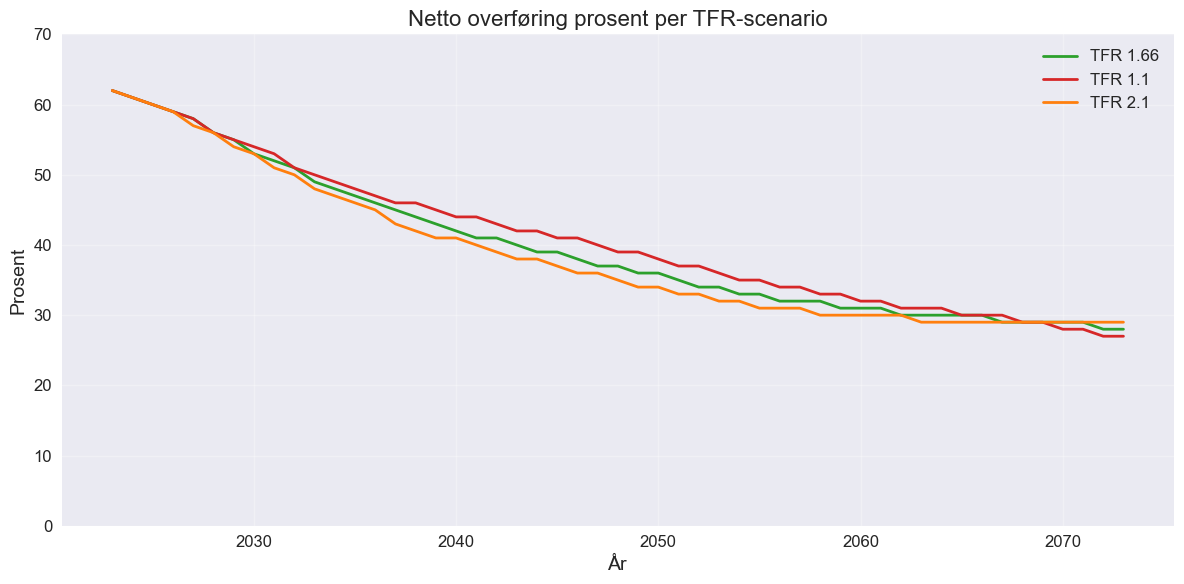

In [141]:
fig, ax = plt.subplots(figsize=(12, 6))

for tfr, color in zip(["TFR 1.66", "TFR 1.1", "TFR 2.1"], [colors_tfr[2], colors_tfr[3], colors_tfr[1]]):
    data = netto_overforing_all.loc[lambda x: x["tfr"] == tfr]
    ax.plot(data["aar"], data["prosent"], label=tfr, color=color, linewidth=2)

ax.set_xlabel('År')
ax.set_ylabel('Prosent')
ax.set_title('Netto overføring prosent per TFR-scenario')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 70)

plt.tight_layout()
plt.show()


In [142]:
data["negativ_sum"] + data["positiv_sum"]

51      325454.76
52      339850.68
53      357256.87
54      377457.74
55      399717.33
56      425675.41
57      450764.32
58      477915.22
59      507068.87
60      537258.57
61      567988.77
62      598237.35
63      628915.03
64      658810.99
65      687860.88
66      715272.83
67      740694.86
68      764229.03
69      786284.07
70      807014.42
71      826611.91
72      844709.61
73      862326.91
74      878823.39
75      895204.88
76      910331.41
77      923753.07
78      936750.03
79      949088.54
80       960239.8
81      971165.96
82      980780.47
83      989392.37
84      997911.47
85     1004909.01
86     1010848.36
87     1015502.29
88     1019384.88
89     1022459.07
90     1024083.02
91     1025522.43
92     1025522.03
93     1025636.71
94     1025188.24
95     1024633.57
96     1024952.46
97     1025350.94
98     1026129.61
99     1026794.28
100    1027072.94
101    1026917.25
dtype: object

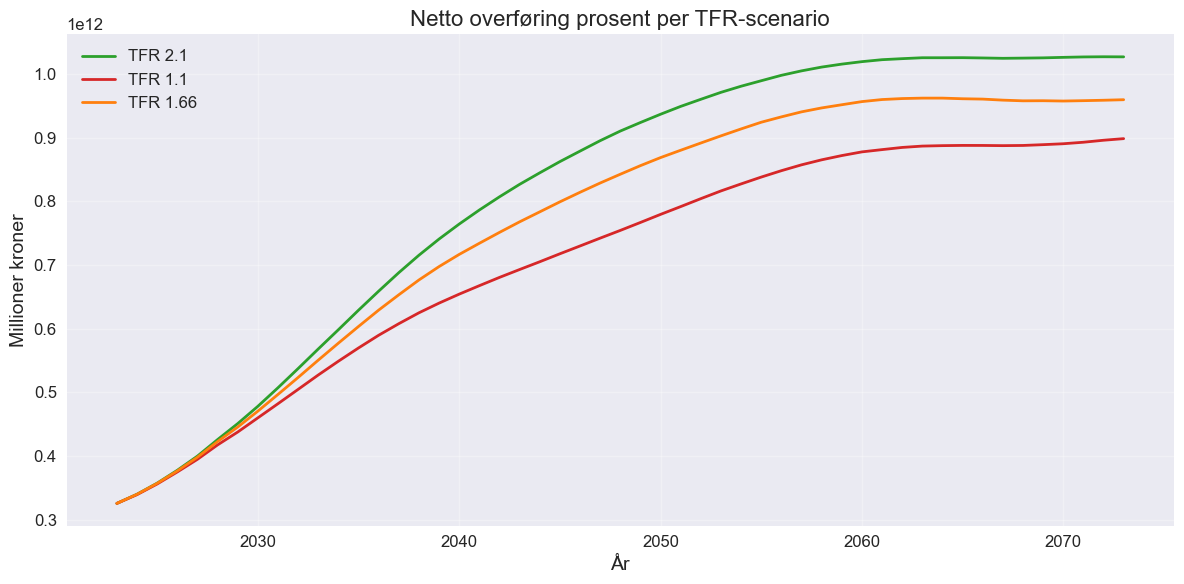

In [154]:
fig, ax = plt.subplots(figsize=(12, 6))

for tfr, color in zip(["TFR 2.1", "TFR 1.1", "TFR 1.66",], [colors_tfr[2], colors_tfr[3], colors_tfr[1]]):
    data = netto_overforing_all.loc[lambda x: x["tfr"] == tfr]

    ax.plot(data["aar"], (data["negativ_sum"] + data["positiv_sum"] )*1e6, label=tfr, color=color, linewidth=2)

ax.set_xlabel('År')
ax.set_ylabel('Millioner kroner')
ax.set_title('Netto overføring prosent per TFR-scenario')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [58]:
pop_total_m_overforing.sum() * 1e6

alder                              5.892000e+09
pop_2023                           5.550459e+12
pop_2055                           5.506377e+12
netto_overforing                   2.739308e+10
netto_overforing_2023              1.443690e+14
netto_overforing_2055              5.187522e+14
netto_overforing_2023_millioner    1.443690e+11
netto_overforing_2055_millioner    5.187522e+11
dtype: float64

In [70]:
pop_3

,sex,alder,pop_2023,pop_2024,pop_2025,pop_2026,pop_2027,pop_2028,pop_2029,pop_2030,...,pop_2064,pop_2065,pop_2066,pop_2067,pop_2068,pop_2069,pop_2070,pop_2071,pop_2072,pop_2073
0,K,0,25310.0,25150.0,24725.0,23891.0,23198.0,22380.0,21897.0,21276.0,...,10526.0,10361.0,10248.0,9831.0,9542.0,9480.0,9293.0,9118.0,8991.0,8982.0
1,K,1,28037.0,25289.0,25130.0,24707.0,23870.0,23180.0,22350.0,21869.0,...,10734.0,10512.0,10352.0,10234.0,9823.0,9536.0,9469.0,9283.0,9107.0,8977.0
2,K,2,26820.0,28015.0,25259.0,25103.0,24675.0,23852.0,23159.0,22326.0,...,11153.0,10719.0,10494.0,10346.0,10229.0,9813.0,9529.0,9463.0,9276.0,9097.0
3,K,3,27466.0,26794.0,27994.0,25230.0,25082.0,24657.0,23831.0,23140.0,...,11391.0,11141.0,10710.0,10483.0,10338.0,10218.0,9801.0,9520.0,9454.0,9267.0
4,K,4,27692.0,27434.0,26768.0,27965.0,25194.0,25050.0,24629.0,23814.0,...,11795.0,11380.0,11131.0,10701.0,10476.0,10322.0,10202.0,9789.0,9513.0,9446.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,M,105,28.0,4.0,3.0,NaN,2.0,1.0,NaN,1.0,...,4.0,5.0,2.0,10.0,8.0,7.0,4.0,3.0,2.0,7.0
216,M,106,NaN,15.0,1.0,1.0,NaN,NaN,NaN,NaN,...,2.0,1.0,NaN,NaN,3.0,5.0,2.0,3.0,NaN,NaN
217,M,107,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,NaN,NaN,NaN,3.0,4.0,NaN,1.0,NaN
218,M,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,NaN,NaN
